In [1]:
# Employee Turnover Problem

import pandas as pd
df = pd.read_csv("employee_turnover.csv")
df.head()

,Job_Satisfaction,Performance_Rating,Years_At_Company,Work_Life_Balance,Distance_From_Home,Monthly_Income,Education_Level,Age,Num_Companies_Worked,Employee_Role,Annual_Bonus,Training_Hours,Department,Annual_Bonus_Squared,Annual_Bonus_Training_Hours_Interaction,Employee_Turnover
0,0.562326,0.141129,0.123989,0.347583,0.330353,0.328853,0.600933,0.315990,0.768736,0.090671,0.324786,0.669193,0.602932,0.105486,0.217344,0
1,0.017041,0.559047,0.511203,0.793908,0.423550,0.553450,0.742009,0.897146,0.380035,0.601633,0.694611,0.043271,0.800761,0.482484,0.030056,0
2,0.774699,0.604371,0.798174,0.260500,0.804034,0.131800,0.775178,0.830947,0.218726,0.972936,0.153476,0.701336,0.705275,0.023555,0.107638,1
3,0.628174,0.385249,0.230104,0.516809,0.272248,0.589249,0.482409,0.090507,0.402746,0.132842,0.305973,0.549688,0.600531,0.093620,0.168190,0
4,0.799183,0.199967,0.839029,0.247927,0.341934,0.076818,0.055356,0.680860,0.923341,0.493017,0.844094,0.793751,0.664679,0.712494,0.670000,0


In [2]:
X = df.drop('Employee_Turnover', axis=1)
y = df['Employee_Turnover']


In [3]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [4]:
# Baseline Logistic Regression
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(max_iter=200)
lr.fit(X_train, y_train)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,200
,multi_class,'deprecated'


In [5]:
# L1 Regularization (Lasso)
lasso = LogisticRegression(penalty='l1', solver='liblinear', C=0.5)
lasso.fit(X_train, y_train)


,penalty,'l1'
,dual,False
,tol,0.0001
,C,0.5
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'liblinear'
,max_iter,100
,multi_class,'deprecated'


In [6]:
# L2 Regularization (Ridge)
ridge = LogisticRegression(penalty='l2', C=1, max_iter=200)
ridge.fit(X_train, y_train)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,200
,multi_class,'deprecated'


In [7]:
# Model Evaluation
from sklearn.metrics import accuracy_score, classification_report

models = {'Baseline': lr, 'Lasso': lasso, 'Ridge': ridge}

for name, model in models.items():
    y_pred = model.predict(X_test)
    print(f"\n{name}")
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred))



Baseline
Accuracy: 0.8592592592592593
              precision    recall  f1-score   support

           0       0.85      0.90      0.87       145
           1       0.87      0.82      0.84       125

    accuracy                           0.86       270
   macro avg       0.86      0.86      0.86       270
weighted avg       0.86      0.86      0.86       270


Lasso
Accuracy: 0.8703703703703703
              precision    recall  f1-score   support

           0       0.86      0.90      0.88       145
           1       0.88      0.83      0.86       125

    accuracy                           0.87       270
   macro avg       0.87      0.87      0.87       270
weighted avg       0.87      0.87      0.87       270


Ridge
Accuracy: 0.8592592592592593
              precision    recall  f1-score   support

           0       0.85      0.90      0.87       145
           1       0.87      0.82      0.84       125

    accuracy                           0.86       270
   macro avg     

In [8]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

models = {
    "Baseline Logistic Regression": lr,
    "L1 Regularization (Lasso)": lasso,
    "L2 Regularization (Ridge)": ridge
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred)
    })

comparison_df = pd.DataFrame(results)
comparison_df = comparison_df.sort_values(
    by="F1 Score", ascending=False
)

comparison_df.round(4)


,Model,Accuracy,Precision,Recall,F1 Score
1,L1 Regularization (Lasso),0.8704,0.8814,0.832,0.856
0,Baseline Logistic Regression,0.8593,0.8718,0.816,0.843
2,L2 Regularization (Ridge),0.8593,0.8718,0.816,0.843


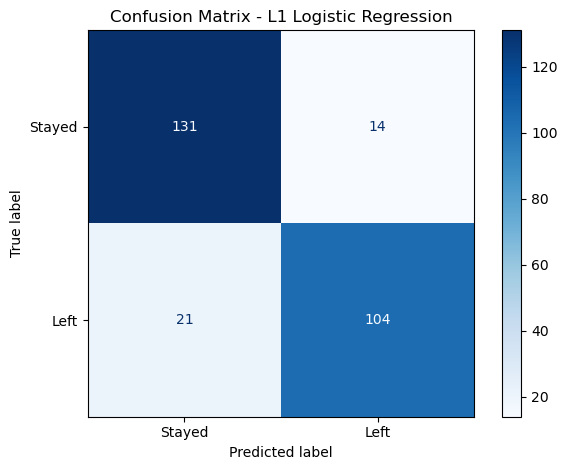

In [9]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

best_model = lasso

y_pred = best_model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Stayed", "Left"],
    cmap="Blues"
)

plt.title("Confusion Matrix - L1 Logistic Regression")
plt.tight_layout()
plt.show()


,Feature,Coefficient,Absolute_Coefficient
4,Distance_From_Home,4.9196,4.9196
0,Job_Satisfaction,4.7491,4.7491
1,Performance_Rating,4.6661,4.6661
3,Work_Life_Balance,4.3711,4.3711
2,Years_At_Company,3.6966,3.6966
6,Education_Level,-0.6070,0.6070
5,Monthly_Income,-0.4084,0.4084
12,Department,-0.1343,0.1343
8,Num_Companies_Worked,-0.0638,0.0638
7,Age,0.0000,0.0000


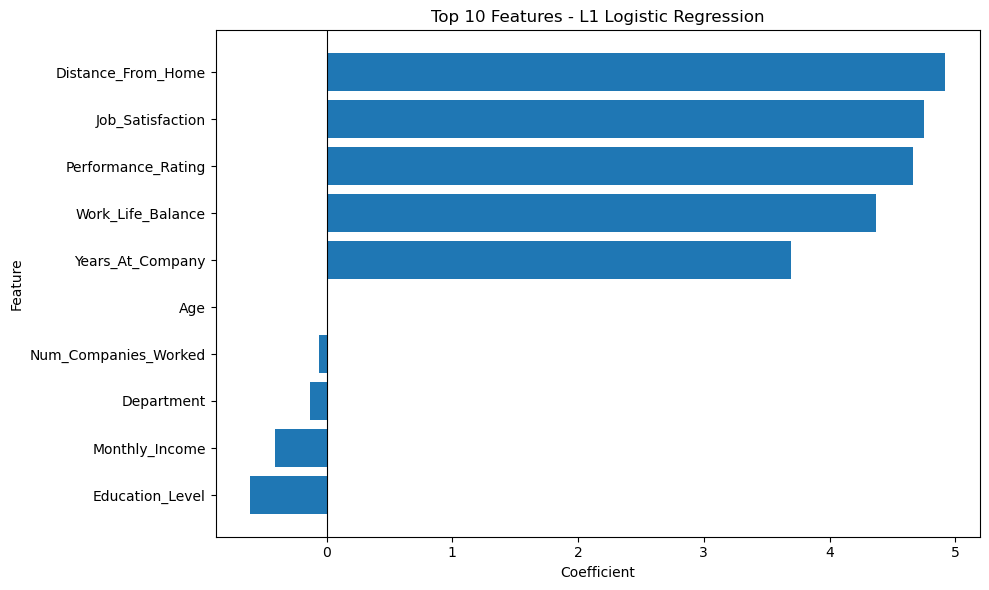

In [10]:

import pandas as pd
import matplotlib.pyplot as plt

coef_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": lasso.coef_[0]
})

coef_df["Absolute_Coefficient"] = coef_df["Coefficient"].abs()

coef_df = coef_df.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

display(coef_df.round(4))

top_features = coef_df.head(10).sort_values("Coefficient")

plt.figure(figsize=(10, 6))
plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Top 10 Features - L1 Logistic Regression")
plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [11]:

from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd

best_model = lasso
y_pred = best_model.predict(X_test)

print("FINAL MODEL: L1 REGULARIZED LOGISTIC REGRESSION")
print("=" * 50)
print(f"Accuracy: {best_model.score(X_test, y_test):.4f}")
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Stayed", "Left"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


FINAL MODEL: L1 REGULARIZED LOGISTIC REGRESSION
Accuracy: 0.8704

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.86      0.90      0.88       145
        Left       0.88      0.83      0.86       125

    accuracy                           0.87       270
   macro avg       0.87      0.87      0.87       270
weighted avg       0.87      0.87      0.87       270


Confusion Matrix:
[[131  14]
 [ 21 104]]



# Conclusion

The objective of this project was to predict employee turnover using Logistic Regression.

Three models were evaluated: Baseline Logistic Regression, L1 Regularization (Lasso), and L2 Regularization (Ridge).

The L1 Regularized Logistic Regression model achieved the highest accuracy of 87.04% and an F1-score of approximately 0.856 on the test dataset.

The confusion matrix showed that the model correctly predicted 131 employees who stayed and 104 employees who left. It incorrectly predicted 14 employees as leaving when they stayed, and missed 21 employees who actually left.

Therefore, L1 Regularization was the best-performing model among the three models evaluated. Further validation would be needed before using the model for real-world HR decisions.


In [12]:
print("Input features:")
print(X.columns.tolist())

print("\nTotal features:", len(X.columns))

Input features:
['Job_Satisfaction', 'Performance_Rating', 'Years_At_Company', 'Work_Life_Balance', 'Distance_From_Home', 'Monthly_Income', 'Education_Level', 'Age', 'Num_Companies_Worked', 'Employee_Role', 'Annual_Bonus', 'Training_Hours', 'Department', 'Annual_Bonus_Squared', 'Annual_Bonus_Training_Hours_Interaction']

Total features: 15


In [13]:

import joblib

model_artifact = {
    "model": lasso,
    "feature_names": X.columns.tolist()
}

joblib.dump(model_artifact, "employee_turnover_model.pkl")

print("Model saved successfully!")
print("File: employee_turnover_model.pkl")
print("Total input features:", len(X.columns))


Model saved successfully!
File: employee_turnover_model.pkl
Total input features: 15
